# Tarea 3 — PyTorch

**Nombre del integrante:** Jonathan Sarli  
**Cédula del integrante:** 30496924

In [16]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# Set device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Output directory and default setup
NOTEBOOK_ID = 3
DATA_DIR = "./data"
MODEL_PREFIX = f"pytorch_fashion_{NOTEBOOK_ID}"

# Class definitions
CLASS_NAMES_10 = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

CLASS_NAMES_4 = ["Top", "Bottom", "Footwear", "Bag"]

# Mapping from 10 classes to 4 simplified classes:
# Top: T-shirt(0), Pullover(2), Coat(4), Shirt(6) -> 0
# Bottom: Trouser(1), Dress(3) -> 1
# Footwear: Sandal(5), Sneaker(7), Ankle boot(9) -> 2
# Bag: Bag(8) -> 3
MAP_10_TO_4 = {
    0: 0, 2: 0, 4: 0, 6: 0,
    1: 1, 3: 1,
    5: 2, 7: 2, 9: 2,
    8: 3
}

In [17]:
class SimplifiedFashionMNIST(Dataset):
    """Custom Dataset wrapper to convert original labels to 4 simplified classes."""
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        image, label = self.base_dataset[idx]
        simplified_label = MAP_10_TO_4[label]
        return image, simplified_label


def get_data_loaders(classification="original", batch_size=64):
    """Downloads and returns DataLoaders for train and test sets."""
    transform = transforms.ToTensor()
    
    train_set = torchvision.datasets.FashionMNIST(
        root=DATA_DIR, train=True, download=True, transform=transform
    )
    test_set = torchvision.datasets.FashionMNIST(
        root=DATA_DIR, train=False, download=True, transform=transform
    )

    if classification == "simplified":
        train_set = SimplifiedFashionMNIST(train_set)
        test_set = SimplifiedFashionMNIST(test_set)

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False)
    
    return train_loader, test_loader

In [18]:
def calculate_layer_neurons(hidden_layers, network_type, neurons_per_layer=512, num_classes=10):
    """Calculates hidden layer neuron counts based on user spec or linear interpolation."""
    if network_type == "rectangular":
        return [neurons_per_layer] * hidden_layers
    elif network_type == "convolutional":
        layers_neurons = []
        for i in range(1, hidden_layers + 1):
            n = round(784 + (num_classes - 784) * i / (hidden_layers + 1))
            layers_neurons.append(n)
        return layers_neurons
    else:
        raise ValueError("Invalid network type. Must be 'rectangular' or 'convolutional'.")


def build_model(hidden_layers=2, network_type="rectangular", neurons_per_layer=512, 
                classification="original", use_bn=True, dropout_rate=0.2):
    """Constructs a Sequential PyTorch model starting with nn.Flatten()."""
    num_classes = 10 if classification == "original" else 4
    layer_sizes = calculate_layer_neurons(hidden_layers, network_type, neurons_per_layer, num_classes)
    
    layers = [nn.Flatten()]
    in_features = 784
    
    for out_features in layer_sizes:
        layers.append(nn.Linear(in_features, out_features))
        if use_bn:
            layers.append(nn.BatchNorm1d(out_features))
        layers.append(nn.ReLU())
        if dropout_rate > 0.0:
            layers.append(nn.Dropout(dropout_rate))
        in_features = out_features
        
    layers.append(nn.Linear(in_features, num_classes))
    return nn.Sequential(*layers)

In [19]:
def train_model(model, train_loader, epochs=10, lr=0.001, weight_decay=1e-4):
    """Trains the neural network and returns loss history."""
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    
    model.to(DEVICE)
    loss_history = []
    
    print(f"\n[INFO] Starting training for {epochs} epoch(s)...")
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * images.size(0)
            
        epoch_loss = running_loss / len(train_loader.dataset)
        loss_history.append(epoch_loss)
        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f}")
        
    return loss_history


def plot_loss(loss_history):
    """Plots training loss curve per epoch."""
    plt.figure(figsize=(8, 4))
    plt.plot(range(1, len(loss_history) + 1), loss_history, marker='o', color='b', label='Training Loss')
    plt.title("Pérdida por Época (Training Loss)")
    plt.xlabel("Época")
    plt.ylabel("Pérdida (Loss)")
    plt.grid(True)
    plt.legend()
    plt.show()


def test_model(model, test_loader, num_classes=10):
    """Evaluates the model and computes accuracy, precision, recall, and confusion matrix."""
    model.eval()
    model.to(DEVICE)
    
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())
            
    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    
    # Compute confusion matrix
    cm = np.zeros((num_classes, num_classes), dtype=int)
    for t, p in zip(all_targets, all_preds):
        cm[t, p] += 1
        
    # Calculate overall metrics
    correct = np.trace(cm)
    total = len(all_targets)
    accuracy = correct / total
    
    precision_per_class = []
    recall_per_class = []
    
    for c in range(num_classes):
        tp = cm[c, c]
        fp = np.sum(cm[:, c]) - tp
        fn = np.sum(cm[c, :]) - tp
        
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        
        precision_per_class.append(prec)
        recall_per_class.append(rec)
        
    macro_precision = np.mean(precision_per_class)
    macro_recall = np.mean(recall_per_class)
    
    class_names = CLASS_NAMES_10 if num_classes == 10 else CLASS_NAMES_4
    
    print("\n" + "="*50)
    print("RESULTADOS DE EVALUACIÓN")
    print("="*50)
    print(f"Accuracy Global: {accuracy * 100:.2f}%")
    print(f"Precision (Macro): {macro_precision * 100:.2f}%")
    print(f"Recall (Macro):    {macro_recall * 100:.2f}%\n")
    
    print("Métricas por Clase:")
    for idx, name in enumerate(class_names):
        print(f" - {name:<15}: Precision = {precision_per_class[idx]*100:.2f}%, Recall = {recall_per_class[idx]*100:.2f}%")
        
    # Plot Confusion Matrix
    fig, ax = plt.subplots(figsize=(8, 6))
    cax = ax.matshow(cm, cmap=plt.cm.Blues)
    fig.colorbar(cax)
    
    ax.set_xticks(range(num_classes))
    ax.set_yticks(range(num_classes))
    ax.set_xticklabels(class_names, rotation=45, ha="left")
    ax.set_yticklabels(class_names)
    
    for i in range(num_classes):
        for j in range(num_classes):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", 
                    color="white" if cm[i, j] > (cm.max() / 2) else "black")
            
    plt.xlabel("Predicción")
    plt.ylabel("Realidad")
    plt.title("Matriz de Confusión", pad=20)
    plt.show()
    
    return accuracy


def save_model_pth(model, hyperparameters, filepath):
    """Saves model state_dict and hyperparameters complying with rubric contract."""
    payload = {
        "state_dict": model.state_dict(),
        "hyperparameters": hyperparameters
    }
    torch.save(payload, filepath)
    print(f"\n[ÉXITO] Modelo guardado en: {filepath}")


def load_model_pth(filepath):
    """Loads a model state_dict and builds model using state_dict shapes."""
    if not os.path.exists(filepath):
        print(f"\n[ERROR] El archivo {filepath} no existe.")
        return None, None
        
    checkpoint = torch.load(filepath, map_location=DEVICE)
    state_dict = checkpoint["state_dict"]
    hyperparameters = checkpoint.get("hyperparameters", {})
    
    # Infer architecture from state_dict shapes
    linear_weights = [v for k, v in state_dict.items() if k.endswith(".weight") and v.ndim == 2]
    
    hidden_layers = len(linear_weights) - 1
    num_classes = linear_weights[-1].shape[0]
    classification = "original" if num_classes == 10 else "simplified"
    
    # Detect optional layers
    use_bn = any("running_mean" in k for k in state_dict.keys())
    dropout_rate = hyperparameters.get("optimizations", {}).get("dropout", 0.2)
    
    neurons_per_layer = linear_weights[0].shape[0]
    network_type = hyperparameters.get("network_type", "rectangular")
    
    model = build_model(
        hidden_layers=hidden_layers,
        network_type=network_type,
        neurons_per_layer=neurons_per_layer,
        classification=classification,
        use_bn=use_bn,
        dropout_rate=dropout_rate
    )
    
    model.load_state_dict(state_dict)
    print(f"\n[ÉXITO] Modelo cargado desde: {filepath}")
    return model, hyperparameters


    MENÚ PRINCIPAL - CLASIFICADOR PYTORCH    
1. Crear una nueva red neuronal
2. Cargar red desde archivo .pth
3. Entrenar la red actual
4. Probar la red (Evaluación)
5. Guardar la red actual en .pth
6. Salir


👉 Seleccione una opción (1-6):
   [Seleccionado]: '1'

--- PASO 1: Tipo de Clasificación ---
1: Original (10 clases)
2: Simplificada (4 clases)

👉 Seleccione opción (defecto 1):
   [Seleccionado]: '1'

--- PASO 2: Tipo de Arquitectura ---
1: Rectangular (mismo número de neuronas por capa)
2: Convolucional / Embudo (interpolación decreciente)

👉 Seleccione opción (defecto 1):
   [Seleccionado]: '2'

--- PASO 3: Número de Capas Ocultas ---

👉 Ingrese cantidad de capas (defecto 2):
   [Seleccionado]: '(Enter / Valor por defecto)'

--- PASO 5: Normalización (Batch Normalization) ---
s: Sí | n: No

👉 ¿Usar Batch Normalization? (defecto s):
   [Seleccionado]: '(Enter / Valor por defecto)'

--- PASO 6: Regularización (Dropout Rate) ---

👉 Ingrese tasa de Dropout (0.0 a 0.5) (defecto 0

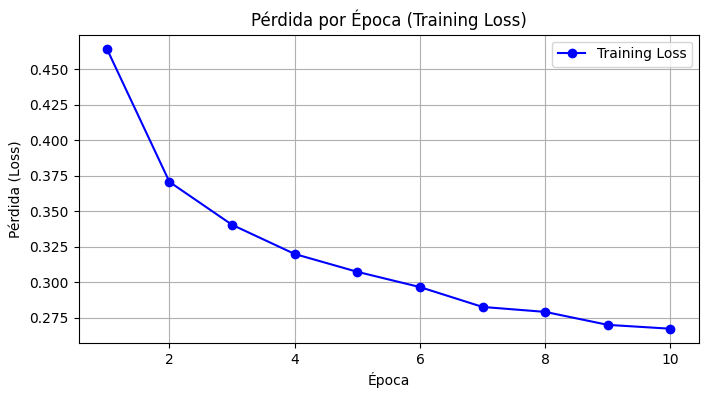


    MENÚ PRINCIPAL - CLASIFICADOR PYTORCH    
1. Crear una nueva red neuronal
2. Cargar red desde archivo .pth
3. Entrenar la red actual
4. Probar la red (Evaluación)
5. Guardar la red actual en .pth
6. Salir


👉 Seleccione una opción (1-6):
   [Seleccionado]: '4'

--- Evaluar Red Actual ---

RESULTADOS DE EVALUACIÓN
Accuracy Global: 88.27%
Precision (Macro): 88.49%
Recall (Macro):    88.27%

Métricas por Clase:
 - T-shirt/top    : Precision = 81.89%, Recall = 85.90%
 - Trouser        : Precision = 99.79%, Recall = 97.00%
 - Pullover       : Precision = 85.63%, Recall = 75.10%
 - Dress          : Precision = 89.22%, Recall = 88.60%
 - Coat           : Precision = 81.59%, Recall = 80.20%
 - Sandal         : Precision = 96.69%, Recall = 96.30%
 - Shirt          : Precision = 67.65%, Recall = 73.40%
 - Sneaker        : Precision = 96.66%, Recall = 89.70%
 - Bag            : Precision = 95.06%, Recall = 98.10%
 - Ankle boot     : Precision = 90.69%, Recall = 98.40%


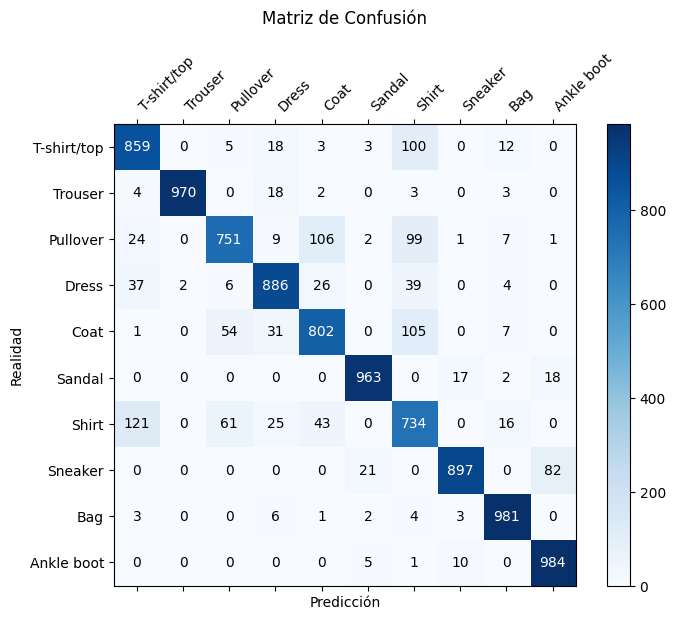


    MENÚ PRINCIPAL - CLASIFICADOR PYTORCH    
1. Crear una nueva red neuronal
2. Cargar red desde archivo .pth
3. Entrenar la red actual
4. Probar la red (Evaluación)
5. Guardar la red actual en .pth
6. Salir


👉 Seleccione una opción (1-6):
   [Seleccionado]: '5'

--- Guardar Modelo ---

👉 Nombre del archivo (Enter para defecto 'pytorch_fashion_3_original_convolutional.pth'):
   [Seleccionado]: 'pytorch_fashion_3_original_convolutional.pth'

[ÉXITO] Modelo guardado en: pytorch_fashion_3_original_convolutional.pth

    MENÚ PRINCIPAL - CLASIFICADOR PYTORCH    
1. Crear una nueva red neuronal
2. Cargar red desde archivo .pth
3. Entrenar la red actual
4. Probar la red (Evaluación)
5. Guardar la red actual en .pth
6. Salir


👉 Seleccione una opción (1-6):
   [Seleccionado]: '1'

--- PASO 1: Tipo de Clasificación ---
1: Original (10 clases)
2: Simplificada (4 clases)

👉 Seleccione opción (defecto 1):
   [Seleccionado]: '2'

--- PASO 2: Tipo de Arquitectura ---
1: Rectangular (mismo número

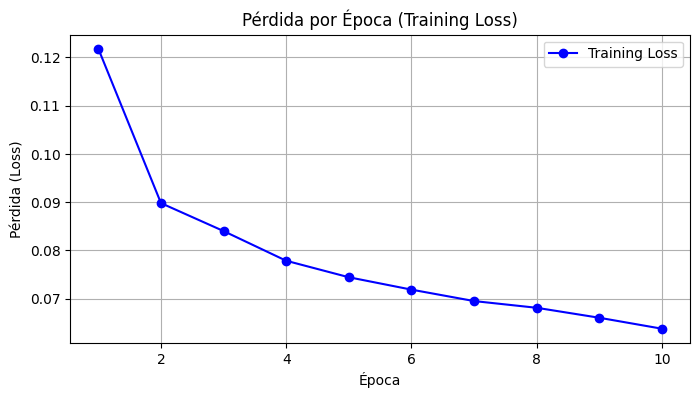


    MENÚ PRINCIPAL - CLASIFICADOR PYTORCH    
1. Crear una nueva red neuronal
2. Cargar red desde archivo .pth
3. Entrenar la red actual
4. Probar la red (Evaluación)
5. Guardar la red actual en .pth
6. Salir


👉 Seleccione una opción (1-6):
   [Seleccionado]: '4'

--- Evaluar Red Actual ---

RESULTADOS DE EVALUACIÓN
Accuracy Global: 96.61%
Precision (Macro): 95.86%
Recall (Macro):    96.92%

Métricas por Clase:
 - Top            : Precision = 97.95%, Recall = 94.20%
 - Bottom         : Precision = 90.28%, Recall = 96.55%
 - Footwear       : Precision = 99.83%, Recall = 99.63%
 - Bag            : Precision = 95.39%, Recall = 97.30%


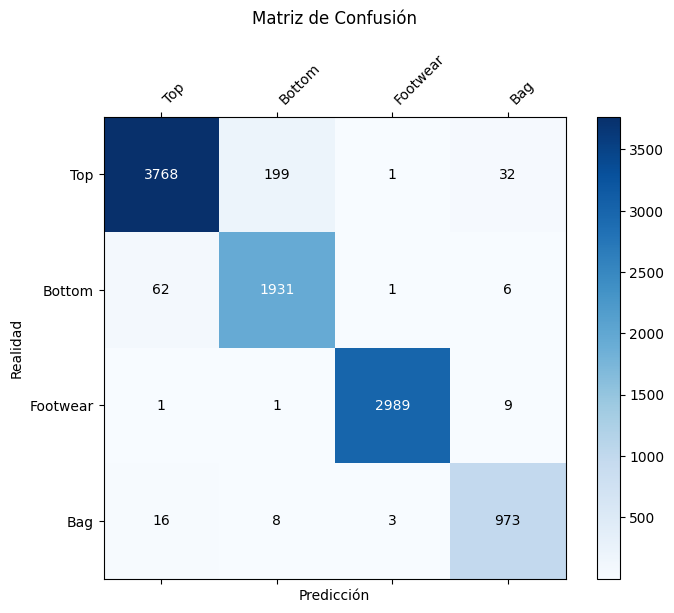


    MENÚ PRINCIPAL - CLASIFICADOR PYTORCH    
1. Crear una nueva red neuronal
2. Cargar red desde archivo .pth
3. Entrenar la red actual
4. Probar la red (Evaluación)
5. Guardar la red actual en .pth
6. Salir


👉 Seleccione una opción (1-6):
   [Seleccionado]: '5'

--- Guardar Modelo ---

👉 Nombre del archivo (Enter para defecto 'pytorch_fashion_3_simplified_rectangular.pth'):
   [Seleccionado]: 'pytorch_fashion_3_simplified_rectangular.pth'

[ÉXITO] Modelo guardado en: pytorch_fashion_3_simplified_rectangular.pth

    MENÚ PRINCIPAL - CLASIFICADOR PYTORCH    
1. Crear una nueva red neuronal
2. Cargar red desde archivo .pth
3. Entrenar la red actual
4. Probar la red (Evaluación)
5. Guardar la red actual en .pth
6. Salir


👉 Seleccione una opción (1-6):
   [Seleccionado]: '1'

--- PASO 1: Tipo de Clasificación ---
1: Original (10 clases)
2: Simplificada (4 clases)

👉 Seleccione opción (defecto 1):
   [Seleccionado]: '2'

--- PASO 2: Tipo de Arquitectura ---
1: Rectangular (mismo número

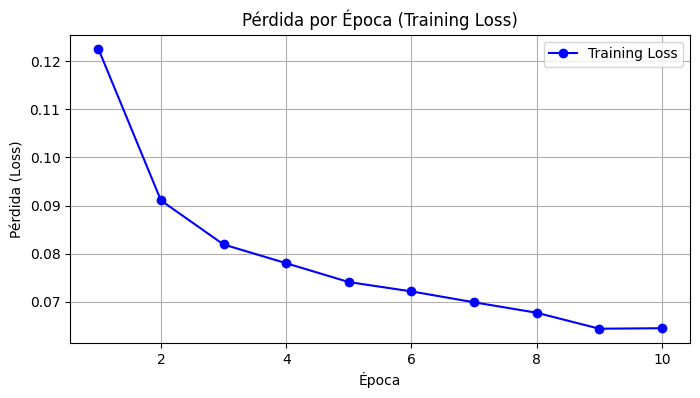


    MENÚ PRINCIPAL - CLASIFICADOR PYTORCH    
1. Crear una nueva red neuronal
2. Cargar red desde archivo .pth
3. Entrenar la red actual
4. Probar la red (Evaluación)
5. Guardar la red actual en .pth
6. Salir


👉 Seleccione una opción (1-6):
   [Seleccionado]: '4'

--- Evaluar Red Actual ---

RESULTADOS DE EVALUACIÓN
Accuracy Global: 97.39%
Precision (Macro): 97.63%
Recall (Macro):    96.76%

Métricas por Clase:
 - Top            : Precision = 95.75%, Recall = 98.10%
 - Bottom         : Precision = 96.76%, Recall = 92.70%
 - Footwear       : Precision = 99.73%, Recall = 99.93%
 - Bag            : Precision = 98.27%, Recall = 96.30%


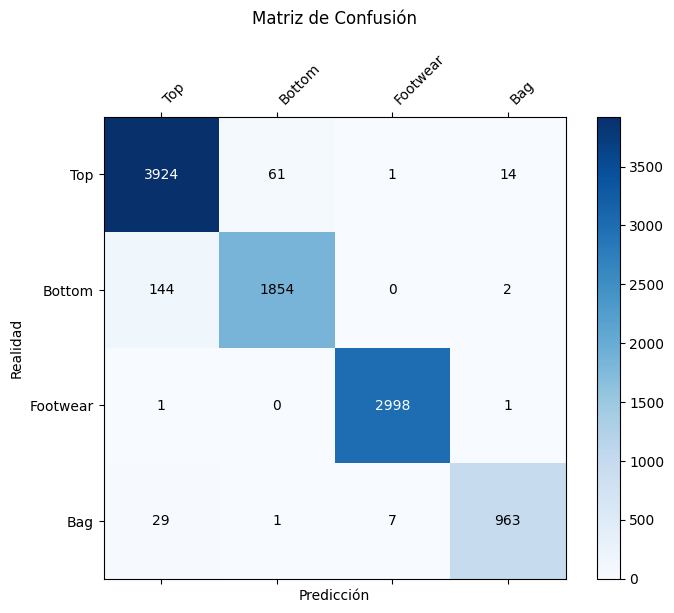


    MENÚ PRINCIPAL - CLASIFICADOR PYTORCH    
1. Crear una nueva red neuronal
2. Cargar red desde archivo .pth
3. Entrenar la red actual
4. Probar la red (Evaluación)
5. Guardar la red actual en .pth
6. Salir


👉 Seleccione una opción (1-6):
   [Seleccionado]: '5'

--- Guardar Modelo ---

👉 Nombre del archivo (Enter para defecto 'pytorch_fashion_3_simplified_convolutional.pth'):
   [Seleccionado]: 'pytorch_fashion_3_simplified_convolutional.pth'

[ÉXITO] Modelo guardado en: pytorch_fashion_3_simplified_convolutional.pth

    MENÚ PRINCIPAL - CLASIFICADOR PYTORCH    
1. Crear una nueva red neuronal
2. Cargar red desde archivo .pth
3. Entrenar la red actual
4. Probar la red (Evaluación)
5. Guardar la red actual en .pth
6. Salir


👉 Seleccione una opción (1-6):
   [Seleccionado]: '2'

--- Cargar Red desde Archivo .pth ---

👉 Ingrese el nombre del archivo .pth:
   [Seleccionado]: 'pytorch_fashion_3_original_rectangular.pth'

[ÉXITO] Modelo cargado desde: pytorch_fashion_3_original_rectang

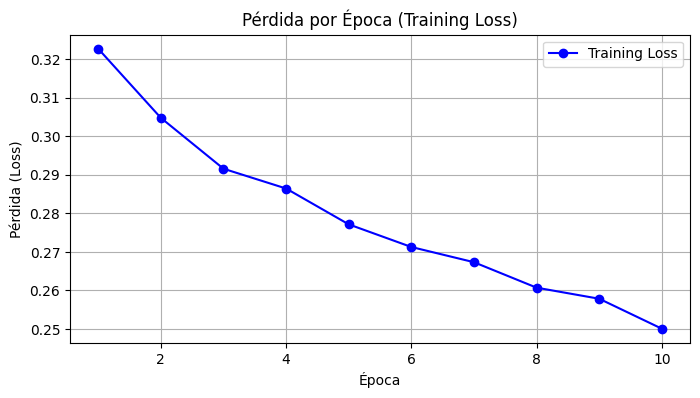


    MENÚ PRINCIPAL - CLASIFICADOR PYTORCH    
1. Crear una nueva red neuronal
2. Cargar red desde archivo .pth
3. Entrenar la red actual
4. Probar la red (Evaluación)
5. Guardar la red actual en .pth
6. Salir


👉 Seleccione una opción (1-6):
   [Seleccionado]: '4'

--- Evaluar Red Actual ---

RESULTADOS DE EVALUACIÓN
Accuracy Global: 88.27%
Precision (Macro): 88.60%
Recall (Macro):    88.27%

Métricas por Clase:
 - T-shirt/top    : Precision = 81.92%, Recall = 87.00%
 - Trouser        : Precision = 98.79%, Recall = 97.60%
 - Pullover       : Precision = 86.66%, Recall = 70.80%
 - Dress          : Precision = 89.19%, Recall = 89.10%
 - Coat           : Precision = 73.22%, Recall = 88.30%
 - Sandal         : Precision = 97.85%, Recall = 95.80%
 - Shirt          : Precision = 70.50%, Recall = 67.40%
 - Sneaker        : Precision = 91.32%, Recall = 97.90%
 - Bag            : Precision = 98.65%, Recall = 95.10%
 - Ankle boot     : Precision = 97.91%, Recall = 93.70%


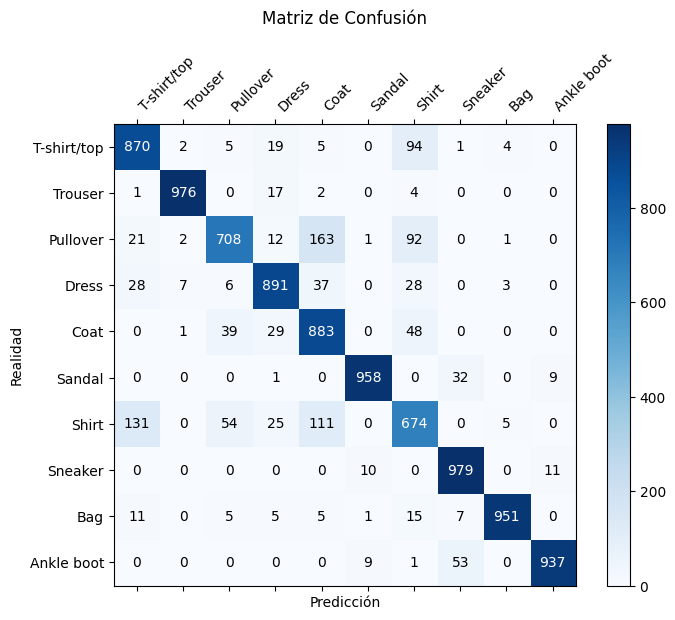


    MENÚ PRINCIPAL - CLASIFICADOR PYTORCH    
1. Crear una nueva red neuronal
2. Cargar red desde archivo .pth
3. Entrenar la red actual
4. Probar la red (Evaluación)
5. Guardar la red actual en .pth
6. Salir


👉 Seleccione una opción (1-6):
   [Seleccionado]: '5'

--- Guardar Modelo ---

👉 Nombre del archivo (Enter para defecto 'pytorch_fashion_3_original_rectangular.pth'):
   [Seleccionado]: 'pytorch_fashion_3_original_rectangular.pth'

[ÉXITO] Modelo guardado en: pytorch_fashion_3_original_rectangular.pth

    MENÚ PRINCIPAL - CLASIFICADOR PYTORCH    
1. Crear una nueva red neuronal
2. Cargar red desde archivo .pth
3. Entrenar la red actual
4. Probar la red (Evaluación)
5. Guardar la red actual en .pth
6. Salir


👉 Seleccione una opción (1-6):


In [ ]:
import sys
import time

def get_input(prompt_text):
    """
    Imprime el mensaje de prompt en la celda de salida, vacía el buffer con flush=True
    y muestra exactamente lo que el usuario ingresó para máxima claridad en VS Code.
    """
    print(f"\n👉 {prompt_text}", flush=True)
    time.sleep(0.1)
    val = input().strip()
    val_disp = val if val != "" else "(Enter / Valor por defecto)"
    print(f"   [Seleccionado]: '{val_disp}'", flush=True)
    return val

def main_menu():
    """Runs the interactive user menu with explicit on-screen prompts."""
    model = None
    hyperparameters = {}
    accumulated_epochs = 0
    
    while True:
        print("\n" + "="*45, flush=True)
        print("    MENÚ PRINCIPAL - CLASIFICADOR PYTORCH    ", flush=True)
        print("="*45, flush=True)
        print("1. Crear una nueva red neuronal", flush=True)
        print("2. Cargar red desde archivo .pth", flush=True)
        print("3. Entrenar la red actual", flush=True)
        print("4. Probar la red (Evaluación)", flush=True)
        print("5. Guardar la red actual en .pth", flush=True)
        print("6. Salir", flush=True)
        print("="*45 + "\n", flush=True)
        
        choice = get_input("Seleccione una opción (1-6):")
        
        if choice == "1":
            print("\n--- PASO 1: Tipo de Clasificación ---", flush=True)
            print("1: Original (10 clases)", flush=True)
            print("2: Simplificada (4 clases)", flush=True)
            c_type = get_input("Seleccione opción (defecto 1):")
            classification = "simplified" if c_type == "2" else "original"
            
            print("\n--- PASO 2: Tipo de Arquitectura ---", flush=True)
            print("1: Rectangular (mismo número de neuronas por capa)", flush=True)
            print("2: Convolucional / Embudo (interpolación decreciente)", flush=True)
            n_type = get_input("Seleccione opción (defecto 1):")
            network_type = "convolutional" if n_type == "2" else "rectangular"
            
            print("\n--- PASO 3: Número de Capas Ocultas ---", flush=True)
            layers_in = get_input("Ingrese cantidad de capas (defecto 2):")
            hidden_layers = int(layers_in) if layers_in.isdigit() and int(layers_in) > 0 else 2
            
            neurons_per_layer = 512
            if network_type == "rectangular":
                print("\n--- PASO 4: Neuronas por Capa ---", flush=True)
                neu_in = get_input("Ingrese cantidad de neuronas (defecto 512):")
                if neu_in.isdigit() and int(neu_in) > 0:
                    neurons_per_layer = int(neu_in)
                    
            print("\n--- PASO 5: Normalización (Batch Normalization) ---", flush=True)
            print("s: Sí | n: No", flush=True)
            bn_in = get_input("¿Usar Batch Normalization? (defecto s):").lower()
            use_bn = False if bn_in == "n" else True
            
            print("\n--- PASO 6: Regularización (Dropout Rate) ---", flush=True)
            drop_in = get_input("Ingrese tasa de Dropout (0.0 a 0.5) (defecto 0.2):")
            try:
                dropout_rate = float(drop_in)
            except ValueError:
                dropout_rate = 0.2
                
            model = build_model(
                hidden_layers=hidden_layers,
                network_type=network_type,
                neurons_per_layer=neurons_per_layer,
                classification=classification,
                use_bn=use_bn,
                dropout_rate=dropout_rate
            )
            
            accumulated_epochs = 0
            num_classes = 10 if classification == "original" else 4
            layer_sizes = calculate_layer_neurons(hidden_layers, network_type, neurons_per_layer, num_classes)
            
            hyperparameters = {
                "network_type": network_type,
                "hidden_layers": hidden_layers,
                "neurons_per_layer": layer_sizes,
                "epochs_trained": 0,
                "classification": classification,
                "optimizations": {
                    "batch_normalization": use_bn,
                    "dropout": dropout_rate,
                    "optimizer": "Adam",
                    "learning_rate": 0.001
                }
            }
            print(f"\n✅ [ÉXITO] Red {network_type} ({classification}) de {hidden_layers} capas creada correctamente.", flush=True)
            print(f"   Estructura de capas ocultas: {layer_sizes}", flush=True)

        elif choice == "2":
            print("\n--- Cargar Red desde Archivo .pth ---", flush=True)
            filename = get_input("Ingrese el nombre del archivo .pth:")
            loaded_model, loaded_hp = load_model_pth(filename)
            if loaded_model is not None:
                model = loaded_model
                hyperparameters = loaded_hp
                accumulated_epochs = hyperparameters.get("epochs_trained", 0)

        elif choice == "3":
            if model is None:
                print("\n⚠️ [ERROR] Debe crear o cargar una red primero.", flush=True)
                continue
                
            print("\n--- Entrenar Red Actual ---", flush=True)
            epochs_in = get_input("Número de épocas a entrenar (defecto 10):")
            epochs = int(epochs_in) if epochs_in.isdigit() and int(epochs_in) > 0 else 10
            
            classification = hyperparameters.get("classification", "original")
            train_loader, _ = get_data_loaders(classification=classification)
            
            lr = hyperparameters.get("optimizations", {}).get("learning_rate", 0.001)
            loss_history = train_model(model, train_loader, epochs=epochs, lr=lr)
            
            accumulated_epochs += epochs
            hyperparameters["epochs_trained"] = accumulated_epochs
            
            plot_loss(loss_history)

        elif choice == "4":
            if model is None:
                print("\n⚠️ [ERROR] Debe crear o cargar una red primero.", flush=True)
                continue
                
            print("\n--- Evaluar Red Actual ---", flush=True)
            classification = hyperparameters.get("classification", "original")
            _, test_loader = get_data_loaders(classification=classification)
            num_classes = 10 if classification == "original" else 4
            
            test_model(model, test_loader, num_classes=num_classes)

        elif choice == "5":
            if model is None:
                print("\n⚠️ [ERROR] Debe crear o cargar una red primero.", flush=True)
                continue
                
            classification = hyperparameters.get("classification", "original")
            network_type = hyperparameters.get("network_type", "rectangular")
            default_filename = f"{MODEL_PREFIX}_{classification}_{network_type}.pth"
            
            print(f"\n--- Guardar Modelo ---", flush=True)
            filename = get_input(f"Nombre del archivo (Enter para defecto '{default_filename}'):")
            if not filename:
                filename = default_filename
                
            save_model_pth(model, hyperparameters, filename)

        elif choice == "6":
            print("\n👋 ¡Hasta luego!", flush=True)
            break
        else:
            print(f"\n⚠️ Opción '{choice}' no válida. Intente de nuevo.", flush=True)

# Start menu
main_menu()